# Entrega proyecto: clasificación

Integrantes Team-12:
* CAMILO MUNOZ HALIFA
* DIEGO ALEJANDRO FIGUEREDO SALAMANCA
* FABIAN ANDRES GULLAVAN VERA
* SILVIA CARDENAS SANTOS

# 1. Selección de modelo de clasificación — UniBank

* **Propósito**

Comparar **tres clasificadores** para predecir `Subscription`. La métrica de la competencia es ROC-AUC; por eso esa será la métrica principal para ordenar los candidatos.

Se seleccionaron regresión logística, análisis discriminante lineal (LDA) y árbol de decisión. No obstante, en otra exploración se encontraron tres modelos (Random Forest, Extra Trees e HistGradientBoosting) que sobresalieron.

* **Criterio de selección**

1. Comparar los tres modelos con validación cruzada estratificada de cinco pliegues, usando las mismas divisiones.
2. Ordenar por ROC-AUC medio; reportar también Average Precision y métricas al umbral 0,5 como información complementaria.
3. Revisar la interpretabilidad y los criterios para la selección del modelo.

La desviación estándar reportada es la variación entre pliegues, no un intervalo de confianza. El archivo de prueba de Kaggle no se usa para elegir ni ajustar el modelo.

## 1.1 Preparar entorno y cargar los datos

Los archivos de la competencia se descargan con `kagglehub`, usando `KAGGLE_API_TOKEN` del archivo `.env`, igual que en el notebook de regresion. Se identifica el CSV de entrenamiento y, si esta disponible, el de prueba.


In [1]:
import os
from pathlib import Path

import kagglehub
import numpy as np
import pandas as pd
from dotenv import load_dotenv

env_path = Path.cwd() / ".env"
if not env_path.is_file():
    raise FileNotFoundError("No se encontro .env")
load_dotenv(env_path, override=True)
if not os.environ.get("KAGGLE_API_TOKEN", "").strip():
    raise ValueError("Falta KAGGLE_API_TOKEN en el archivo .env.")

data_dir = Path(kagglehub.competition_download("mae-competencia-clasificacion-202620"))
print("Path to competition files:", data_dir)
csv_files = [file.name for file in data_dir.iterdir() if file.suffix.lower() == '.csv']
train_name = next((name for name in csv_files if 'train' in name.lower()), None)
if train_name is None:
    raise FileNotFoundError("No se encontro el archivo Train bank.csv en la descarga.")
train = pd.read_csv(data_dir / train_name)

test_name = next((name for name in csv_files if 'test' in name.lower()), None)
if test_name:
    test = pd.read_csv(data_dir / test_name)
else:
    test = pd.DataFrame(columns=train.drop(columns=['Subscription'], errors='ignore').columns)

TARGET = 'Subscription'
ID = 'id'
if TARGET not in train.columns:
    raise KeyError(f"No se encontró la variable objetivo '{TARGET}'.")
y = train[TARGET].astype(int)
X = train.drop(columns=[TARGET, ID], errors='ignore')
print('Entrenamiento:', train_name, train.shape)
print('Prueba Kaggle:', test_name if test_name else 'no cargada', test.shape)
print('Distribución de Subscription:')
print(y.value_counts().sort_index())

D:\proyecto-mae\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Path to competition files: C:\Users\Silvi\.cache\kagglehub\competitions\mae-competencia-clasificacion-202620
Entrenamiento: Train bank.csv (31648, 18)
Prueba Kaggle: Test bank.csv (13563, 17)
Distribución de Subscription:
Subscription
0    27951
1     3697
Name: count, dtype: int64


## 1.2 Perfil de calidad y clase objetivo

In [2]:
perfil = pd.DataFrame({
    'Conjunto': ['Entrenamiento', 'Prueba Kaggle'],
    'Filas': [len(train), len(test)],
    'Columnas': [train.shape[1], test.shape[1]],
    'Valores faltantes': [int(train.isna().sum().sum()), int(test.isna().sum().sum())],
    'Filas duplicadas': [int(train.duplicated().sum()), int(test.duplicated().sum())],
})
display(perfil)
display(pd.DataFrame({
    'Subscription': y.value_counts().sort_index().index,
    'Casos': y.value_counts().sort_index().values,
    'Proporción': y.value_counts(normalize=True).sort_index().values,
}))

,Conjunto,Filas,Columnas,Valores faltantes,Filas duplicadas
0,Entrenamiento,31648,18,0,0
1,Prueba Kaggle,13563,17,0,0


,Subscription,Casos,Proporción
0,0,27951,0.883184
1,1,3697,0.116816


## 1.3 Preprocesamiento y tres clasificadores

La imputación y la codificación se ajustan dentro de cada pliegue para evitar filtración entre entrenamiento y validación. Las variables numéricas se imputan con mediana y se estandarizan; las categóricas se imputan con la moda y se convierten a indicadores. El árbol no requiere escalamiento, pero se mantiene el mismo preprocesamiento categórico para que todos reciban las mismas variables.

**Configuraciones comparadas:**

- **Regresión logística:** `class_weight='balanced'`, que compensa el desbalance. En la exploración previa, el peso balanceado dio AUC ≈ 0,9061; los pesos 1:8 quedaron prácticamente iguales.
- **LDA:** `solver='lsqr'` y `shrinkage='auto'`, configuración ya comparada en el notebook anterior.
- **Árbol de decisión:** criterio Gini, `max_depth=10`, `min_samples_leaf=20` y clase balanceada. La profundidad limita la complejidad y el tamaño mínimo de hoja ayuda a evitar particiones con muy pocos casos.

Las métricas de precisión, recall, F1 y balanced accuracy usan el umbral predeterminado 0,5. Se comparan las probabilidades con ROC-AUC, no las etiquetas 0/1.

In [3]:
from sklearn.compose import ColumnTransformer
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import make_scorer, precision_score, recall_score, f1_score, balanced_accuracy_score
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
import matplotlib.pyplot as plt
import seaborn as sns

numeric_cols = X.select_dtypes(include=np.number).columns.tolist()
categorical_cols = [c for c in X.columns if c not in numeric_cols]

def make_preprocessor(columns):
    nums = [c for c in numeric_cols if c in columns]
    cats = [c for c in categorical_cols if c in columns]
    try:
        encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
    except TypeError:  # Compatibilidad con versiones anteriores de scikit-learn en Colab
        encoder = OneHotEncoder(handle_unknown='ignore', sparse=False)
    return ColumnTransformer([
        ('numeric', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scale', StandardScaler())
        ]), nums),
        ('categorical', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('onehot', encoder)
        ]), cats),
    ], remainder='drop')

model_specs = [
    ('Regresión logística balanceada', LogisticRegression(
        max_iter=2000, C=1.0, solver='liblinear', class_weight='balanced'
    )),
    ('LDA con shrinkage automático', LinearDiscriminantAnalysis(
        solver='lsqr', shrinkage='auto'
    )),
    ('Árbol de decisión balanceado', DecisionTreeClassifier(
        criterion='gini', max_depth=10, min_samples_leaf=20,
        class_weight='balanced', random_state=2026
    )),
]

scoring = {
    'auc': 'roc_auc',
    'average_precision': 'average_precision',
    'precision': make_scorer(precision_score, zero_division=0),
    'recall': make_scorer(recall_score, zero_division=0),
    'f1': make_scorer(f1_score, zero_division=0),
    'balanced_accuracy': make_scorer(balanced_accuracy_score),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=2026)
print('Modelos que se evaluarán:', len(model_specs))
print('Pliegues por modelo:', cv.n_splits)

Modelos que se evaluarán: 3
Pliegues por modelo: 5


## 1.4 Evaluar con validación cruzada

Esta celda calcula la media y la desviación estándar de cada métrica sobre cinco pliegues. Ejecute las celdas en orden para regenerar los resultados.

In [4]:
rows = []
fold_results = []
for name, estimator in model_specs:
    pipeline = Pipeline([
        ('prep', make_preprocessor(list(X.columns))),
        ('model', estimator),
    ])
    scores = cross_validate(
        pipeline, X, y, cv=cv, scoring=scoring,
        n_jobs=1, return_train_score=False, error_score='raise'
    )
    row = {'modelo': name}
    for metric in scoring:
        values = scores['test_' + metric]
        row[metric + '_media'] = float(np.mean(values))
        row[metric + '_sd'] = float(np.std(values, ddof=1))
    rows.append(row)
    for fold in range(cv.n_splits):
        fold_results.append({
            'modelo': name, 'pliegue': fold + 1,
            **{metric: float(scores['test_' + metric][fold]) for metric in scoring}
        })

resultados = pd.DataFrame(rows).sort_values('auc_media', ascending=False).reset_index(drop=True)
resultados_por_pliegue = pd.DataFrame(fold_results)
display(resultados.round(4))

,modelo,auc_media,auc_sd,average_precision_media,average_precision_sd,precision_media,precision_sd,recall_media,recall_sd,f1_media,f1_sd,balanced_accuracy_media,balanced_accuracy_sd
0,Regresión logística balanceada,0.9061,0.0037,0.5411,0.0091,0.4102,0.0123,0.8136,0.0119,0.5453,0.0113,0.8294,0.0063
1,LDA con shrinkage automático,0.9034,0.0042,0.5458,0.0154,0.6029,0.0177,0.4276,0.0091,0.5003,0.0098,0.6952,0.0047
2,Árbol de decisión balanceado,0.8881,0.0091,0.5187,0.0122,0.3751,0.0173,0.8483,0.0192,0.5199,0.0156,0.8304,0.0082


## 1.5 Gráficas para comparar los modelos

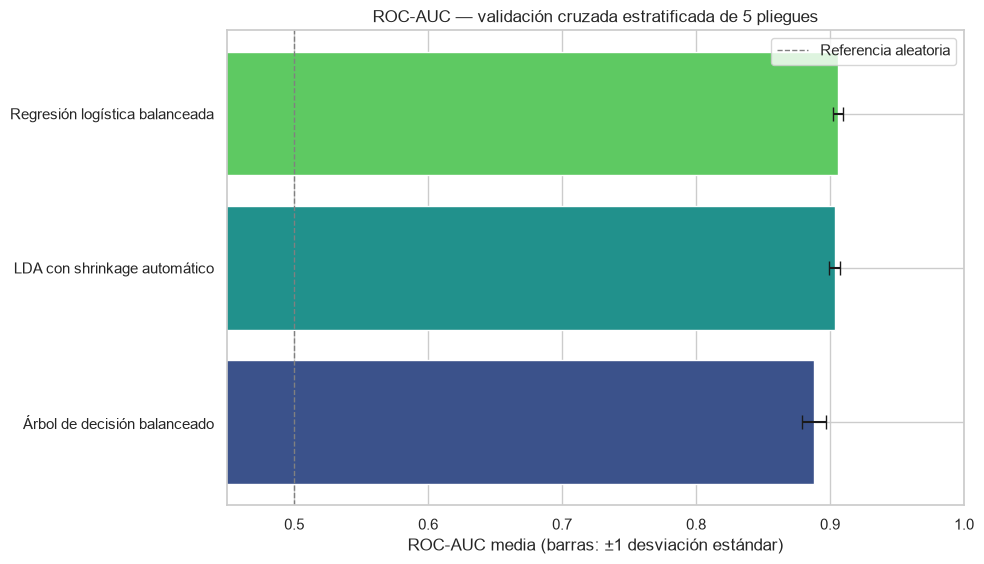

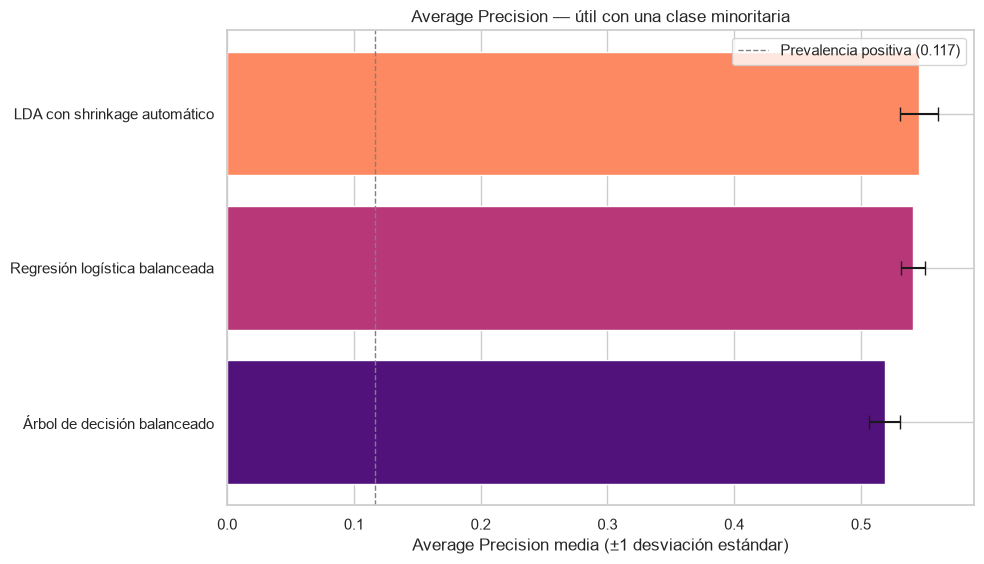

In [5]:
sns.set_theme(style='whitegrid', context='notebook')
orden = resultados.sort_values('auc_media')
fig, ax = plt.subplots(figsize=(10, 5.8))
ax.barh(orden.modelo, orden.auc_media, xerr=orden.auc_sd,
        color=sns.color_palette('viridis', len(orden)), capsize=5)
ax.axvline(0.5, color='gray', linestyle='--', linewidth=1, label='Referencia aleatoria')
ax.set_xlim(0.45, 1.0)
ax.set_xlabel('ROC-AUC media (barras: ±1 desviación estándar)')
ax.set_title('ROC-AUC — validación cruzada estratificada de 5 pliegues')
ax.legend()
plt.tight_layout()
plt.show()

orden_ap = resultados.sort_values('average_precision_media')
fig, ax = plt.subplots(figsize=(10, 5.8))
ax.barh(orden_ap.modelo, orden_ap.average_precision_media,
        xerr=orden_ap.average_precision_sd,
        color=sns.color_palette('magma', len(orden_ap)), capsize=5)
ax.axvline(y.mean(), color='gray', linestyle='--', linewidth=1,
           label=f'Prevalencia positiva ({y.mean():.3f})')
ax.set_xlabel('Average Precision media (±1 desviación estándar)')
ax.set_title('Average Precision — útil con una clase minoritaria')
ax.legend()
plt.tight_layout()
plt.show()

## 1.6 Lectura de la corrida incluida y recomendación preliminar

En esta comparación, la regresión logística balanceada conserva el mejor AUC de los tres candidatos. LDA queda muy cerca en AUC y ofrece una formulación estadística distinta; el árbol de decisión ofrece reglas más intuitivas, pero su desempeño depende de la profundidad y puede perder capacidad de ordenamiento.

La tabla siguiente recoge los valores de la corrida reproducible con los archivos del grupo. Los resultados pueden variar levemente con la versión de scikit-learn o la configuración de ejecución.

In [6]:
# Tabla de la corrida incluida; al ejecutar la sección 4 se recalcula `resultados`.
cols = ['modelo', 'auc_media', 'auc_sd', 'average_precision_media',
        'precision_media', 'recall_media', 'f1_media', 'balanced_accuracy_media']
display(resultados[cols].round(4))

,modelo,auc_media,auc_sd,average_precision_media,precision_media,recall_media,f1_media,balanced_accuracy_media
0,Regresión logística balanceada,0.9061,0.0037,0.5411,0.4102,0.8136,0.5453,0.8294
1,LDA con shrinkage automático,0.9034,0.0042,0.5458,0.6029,0.4276,0.5003,0.6952
2,Árbol de decisión balanceado,0.8881,0.0091,0.5187,0.3751,0.8483,0.5199,0.8304


* **Resumen:**
Se seleccionó preliminarmente la regresión logística balanceada porque obtuvo el mayor ROC-AUC promedio en validación cruzada estratificada de cinco pliegues entre las tres configuraciones evaluadas. Su ventaja frente a LDA fue pequeña; por ello, se mantiene como el modelo principal, sin afirmar una superioridad concluyente.

# 2. Estimación de los parámetros del modelo


## 2.1 Metodo de estimacion y alcance

Partiendo de la **regresion logistica balanceada** escogida en la seccion 1, con las mismas variables, imputacion, estandarizacion, indicadores, `C=1.0` y `solver='liblinear'`. Una vez comparados los candidatos por validacion cruzada, se reajusta esta configuracion con todo `X, y` para estimar sus parametros definitivos. El archivo de prueba no interviene en la estimacion.

El modelo expresa linealmente el logaritmo de los odds:

$$\eta_i=\beta_0+\sum_{j=1}^{k}\beta_j z_{ij},\qquad p_i=\frac{1}{1+e^{-\eta_i}}.$$

Aqui $z_{ij}$ es el predictor transformado. La clase usa maxima verosimilitud; la configuracion seleccionada emplea **log-verosimilitud ponderada y penalizacion L2**. Los pesos de clase son $w_c=n/(2n_c)$ y la contribucion de cada observacion es $w_{y_i}[y_i\log(p_i)+(1-y_i)\log(1-p_i)]$. `C` controla inversamente la intensidad de regularizacion; con `liblinear` tambien se penaliza el intercepto sintetico. Por tanto, los coeficientes no son estimadores de maxima verosimilitud ordinaria sin penalizacion.

In [7]:
from sklearn.base import clone
from sklearn.exceptions import ConvergenceWarning
from scipy.special import expit
import warnings

# Recuperar exactamente la configuracion seleccionada, sin modificar model_specs.
nombre_modelo_final, especificacion_final = next(
    (nombre, estimador) for nombre, estimador in model_specs
    if isinstance(estimador, LogisticRegression)
)
modelo_final = Pipeline([
    ('prep', make_preprocessor(list(X.columns))),
    ('model', clone(especificacion_final)),
])
with warnings.catch_warnings(record=True) as avisos_ajuste:
    warnings.simplefilter('always', ConvergenceWarning)
    modelo_final.fit(X, y)
if any(issubclass(aviso.category, ConvergenceWarning) for aviso in avisos_ajuste):
    raise RuntimeError('El ajuste no convergio; revisar antes de interpretar los parametros.')

preprocesador_final = modelo_final.named_steps['prep']
logistica_final = modelo_final.named_steps['model']
nombres_parametros = preprocesador_final.get_feature_names_out()
beta_transformado = logistica_final.coef_[0]
intercepto_transformado = float(logistica_final.intercept_[0])
assert np.array_equal(logistica_final.classes_, [0, 1])

pesos_clase = len(y) / (2 * y.value_counts().sort_index())
print('Modelo:', nombre_modelo_final)
print('Observaciones:', len(y))
print('Coeficientes e intercepto:', len(beta_transformado) + 1)
print('Iteraciones:', logistica_final.n_iter_.tolist())
print('Pesos por clase:', pesos_clase.to_dict())
tabla_parametros = pd.DataFrame({
    'Parametro': ['Intercepto'] + list(nombres_parametros),
    'Coeficiente': np.r_[intercepto_transformado, beta_transformado],
})
display(tabla_parametros.round(6))

Modelo: Regresión logística balanceada
Observaciones: 31648
Coeficientes e intercepto: 52
Iteraciones: [6]
Pesos por clase: {0: 0.5661335909269793, 1: 4.280227211252367}


,Parametro,Coeficiente
0,Intercepto,-0.029825
1,numeric__Age,0.033714
2,numeric__Balance..euros.,0.070065
3,numeric__Last.Contact.Day,0.022712
4,numeric__Last.Contact.Duration,1.470205
5,numeric__Campaign,-0.324101
6,numeric__Pdays,0.010707
7,numeric__Previous,0.059227
8,categorical__Job_admin.,0.194121
9,categorical__Job_blue-collar,-0.158789


## 2.2 Parametros en unidades originales y contrastes entre categorias

Los coeficientes numericos anteriores corresponden a un aumento de una desviacion estandar. Se dividen por la escala de `StandardScaler` y se corrige el intercepto para expresar la misma ecuacion en unidades originales (despues de imputar).

Se conservaron todos los indicadores categoricos porque asi se comparo el modelo. Para interpretar una categoria frente a otra, se toma como referencia el primer nivel del codificador y se calcula la diferencia entre ambos coeficientes. Se suma al intercepto el coeficiente de cada referencia. Esta es una reexpresion exacta del ajuste, sin volver a estimar ni cambiar predicciones.

En la tabla, `exp(Coeficiente)` es el **odds ratio** por unidad numerica o frente a la categoria de referencia, manteniendo constantes los demas predictores. No es un cambio porcentual directo de la probabilidad ni demuestra causalidad. La ponderacion de clases tampoco garantiza probabilidades calibradas a la prevalencia original. No se reportan p-values ni intervalos clasicos para estos coeficientes penalizados.


In [8]:
beta_original = beta_transformado.copy()
intercepto_original = intercepto_transformado
filas_parametros = []
if numeric_cols:
    escalador_final = preprocesador_final.named_transformers_['numeric'].named_steps['scale']
    cantidad_numericas = len(numeric_cols)
    beta_original[:cantidad_numericas] /= escalador_final.scale_
    intercepto_original -= float(np.dot(beta_original[:cantidad_numericas], escalador_final.mean_))
    for columna, coeficiente in zip(numeric_cols, beta_original[:cantidad_numericas]):
        filas_parametros.append({'Termino': columna, 'Comparacion': 'Por una unidad adicional',
                                 'Coeficiente': coeficiente})
else:
    cantidad_numericas = 0

referencias_categoricas = []
intercepto_referencia = intercepto_original
posicion = cantidad_numericas
if categorical_cols:
    codificador_final = preprocesador_final.named_transformers_['categorical'].named_steps['onehot']
    for columna, niveles in zip(categorical_cols, codificador_final.categories_):
        coeficientes = beta_original[posicion:posicion + len(niveles)]
        referencia = niveles[0]
        intercepto_referencia += float(coeficientes[0])
        referencias_categoricas.append({'Variable': columna, 'Referencia': referencia})
        for nivel, coeficiente in zip(niveles[1:], coeficientes[1:]):
            filas_parametros.append({'Termino': f'{columna}={nivel}',
                                     'Comparacion': f'Frente a {referencia}',
                                     'Coeficiente': float(coeficiente - coeficientes[0])})
        posicion += len(niveles)

tabla_parametros_originales = pd.DataFrame(filas_parametros)
tabla_parametros_originales['Odds ratio'] = np.exp(tabla_parametros_originales['Coeficiente'])
print(f'Intercepto con categorias de referencia: {intercepto_referencia:.6f}')
print('El intercepto corresponde a numericas iguales a cero y categorias de referencia; puede ser un perfil poco realista.')
display(pd.DataFrame(referencias_categoricas))
display(tabla_parametros_originales.round(6))


Intercepto con categorias de referencia: -0.857935
El intercepto corresponde a numericas iguales a cero y categorias de referencia; puede ser un perfil poco realista.


,Variable,Referencia
0,Job,admin.
1,Marital.Status,divorced
2,Education,primary
3,Credit,no
4,Housing.Loan,no
5,Personal.Loan,no
6,Contact,cellular
7,Last.Contact.Month,apr
8,Poutcome,failure


,Termino,Comparacion,Coeficiente,Odds ratio
0,Age,Por una unidad adicional,0.003176,1.003181
1,Balance..euros.,Por una unidad adicional,0.000023,1.000023
2,Last.Contact.Day,Por una unidad adicional,0.002728,1.002731
3,Last.Contact.Duration,Por una unidad adicional,0.005763,1.005780
4,Campaign,Por una unidad adicional,-0.104004,0.901222
5,Pdays,Por una unidad adicional,0.000107,1.000107
6,Previous,Por una unidad adicional,0.023917,1.024205
7,Job=blue-collar,Frente a admin.,-0.352910,0.702640
8,Job=entrepreneur,Frente a admin.,-0.518656,0.595320
9,Job=housemaid,Frente a admin.,-0.590276,0.554174


## 2.3 Verificacion de la ecuacion estimada

Se reconstruye el logit y la funcion logistica para las primeras cinco observaciones y se comparan con `decision_function` y `predict_proba`. Esta comprobacion verifica la extraccion de parametros; no es una evaluacion de generalizacion. El desempeno fuera del ajuste sigue siendo el obtenido por validacion cruzada en la seccion 1. Las filas siguientes pertenecen al entrenamiento.

La ecuacion en unidades originales utiliza las numericas imputadas y todos los indicadores originales. La tabla de contrastes anterior expresa la misma ecuacion para categorias conocidas, usando referencias.


In [9]:
muestra_parametros = X.iloc[:5]
z_muestra = preprocesador_final.transform(muestra_parametros)
logit_manual = intercepto_transformado + z_muestra @ beta_transformado
probabilidad_manual = expit(logit_manual)
probabilidad_pipeline = modelo_final.predict_proba(muestra_parametros)[:, 1]

# Comprobar tambien la conversion a unidades originales.
z_original = z_muestra.copy()
if numeric_cols:
    z_original[:, :cantidad_numericas] = (
        z_muestra[:, :cantidad_numericas] * escalador_final.scale_ + escalador_final.mean_
    )
logit_original = intercepto_original + z_original @ beta_original
assert np.allclose(logit_manual, modelo_final.decision_function(muestra_parametros))
assert np.allclose(logit_original, logit_manual)
assert np.allclose(probabilidad_manual, probabilidad_pipeline)
comprobacion_parametros = pd.DataFrame({
    'Subscription observada': y.iloc[:5].to_numpy(),
    'Logit estimado': logit_manual,
    'Probabilidad manual': probabilidad_manual,
    'Probabilidad pipeline': probabilidad_pipeline,
}, index=muestra_parametros.index)
display(comprobacion_parametros.round(6))
print('Verificacion correcta: la ecuacion y el pipeline producen las mismas probabilidades.')


,Subscription observada,Logit estimado,Probabilidad manual,Probabilidad pipeline
0,0,-2.439460,0.080213,0.080213
1,0,-3.038342,0.045723,0.045723
2,0,-4.740752,0.008656,0.008656
3,0,-3.729951,0.023432,0.023432
4,0,-3.258983,0.037005,0.037005


Verificacion correcta: la ecuacion y el pipeline producen las mismas probabilidades.


## 2.4 Odds ratios por variable y grupo de categorias

Cada punto representa un odds ratio estimado. La linea vertical en **OR = 1** indica ausencia de cambio en los odds; valores mayores que 1 indican aumento y menores que 1, disminucion, manteniendo constantes los demas predictores. El eje horizontal usa escala logaritmica.

Las variables numericas se muestran por una unidad en su escala original; cada grupo categorico se compara con la referencia indicada en su titulo. Por ejemplo, OR = 2 significa que los odds se duplican, no que la probabilidad se duplique. Las magnitudes entre variables con unidades distintas no constituyen un ranking de importancia. Se muestran estimaciones puntuales penalizadas, sin intervalos de confianza ni afirmaciones de significancia estadistica.


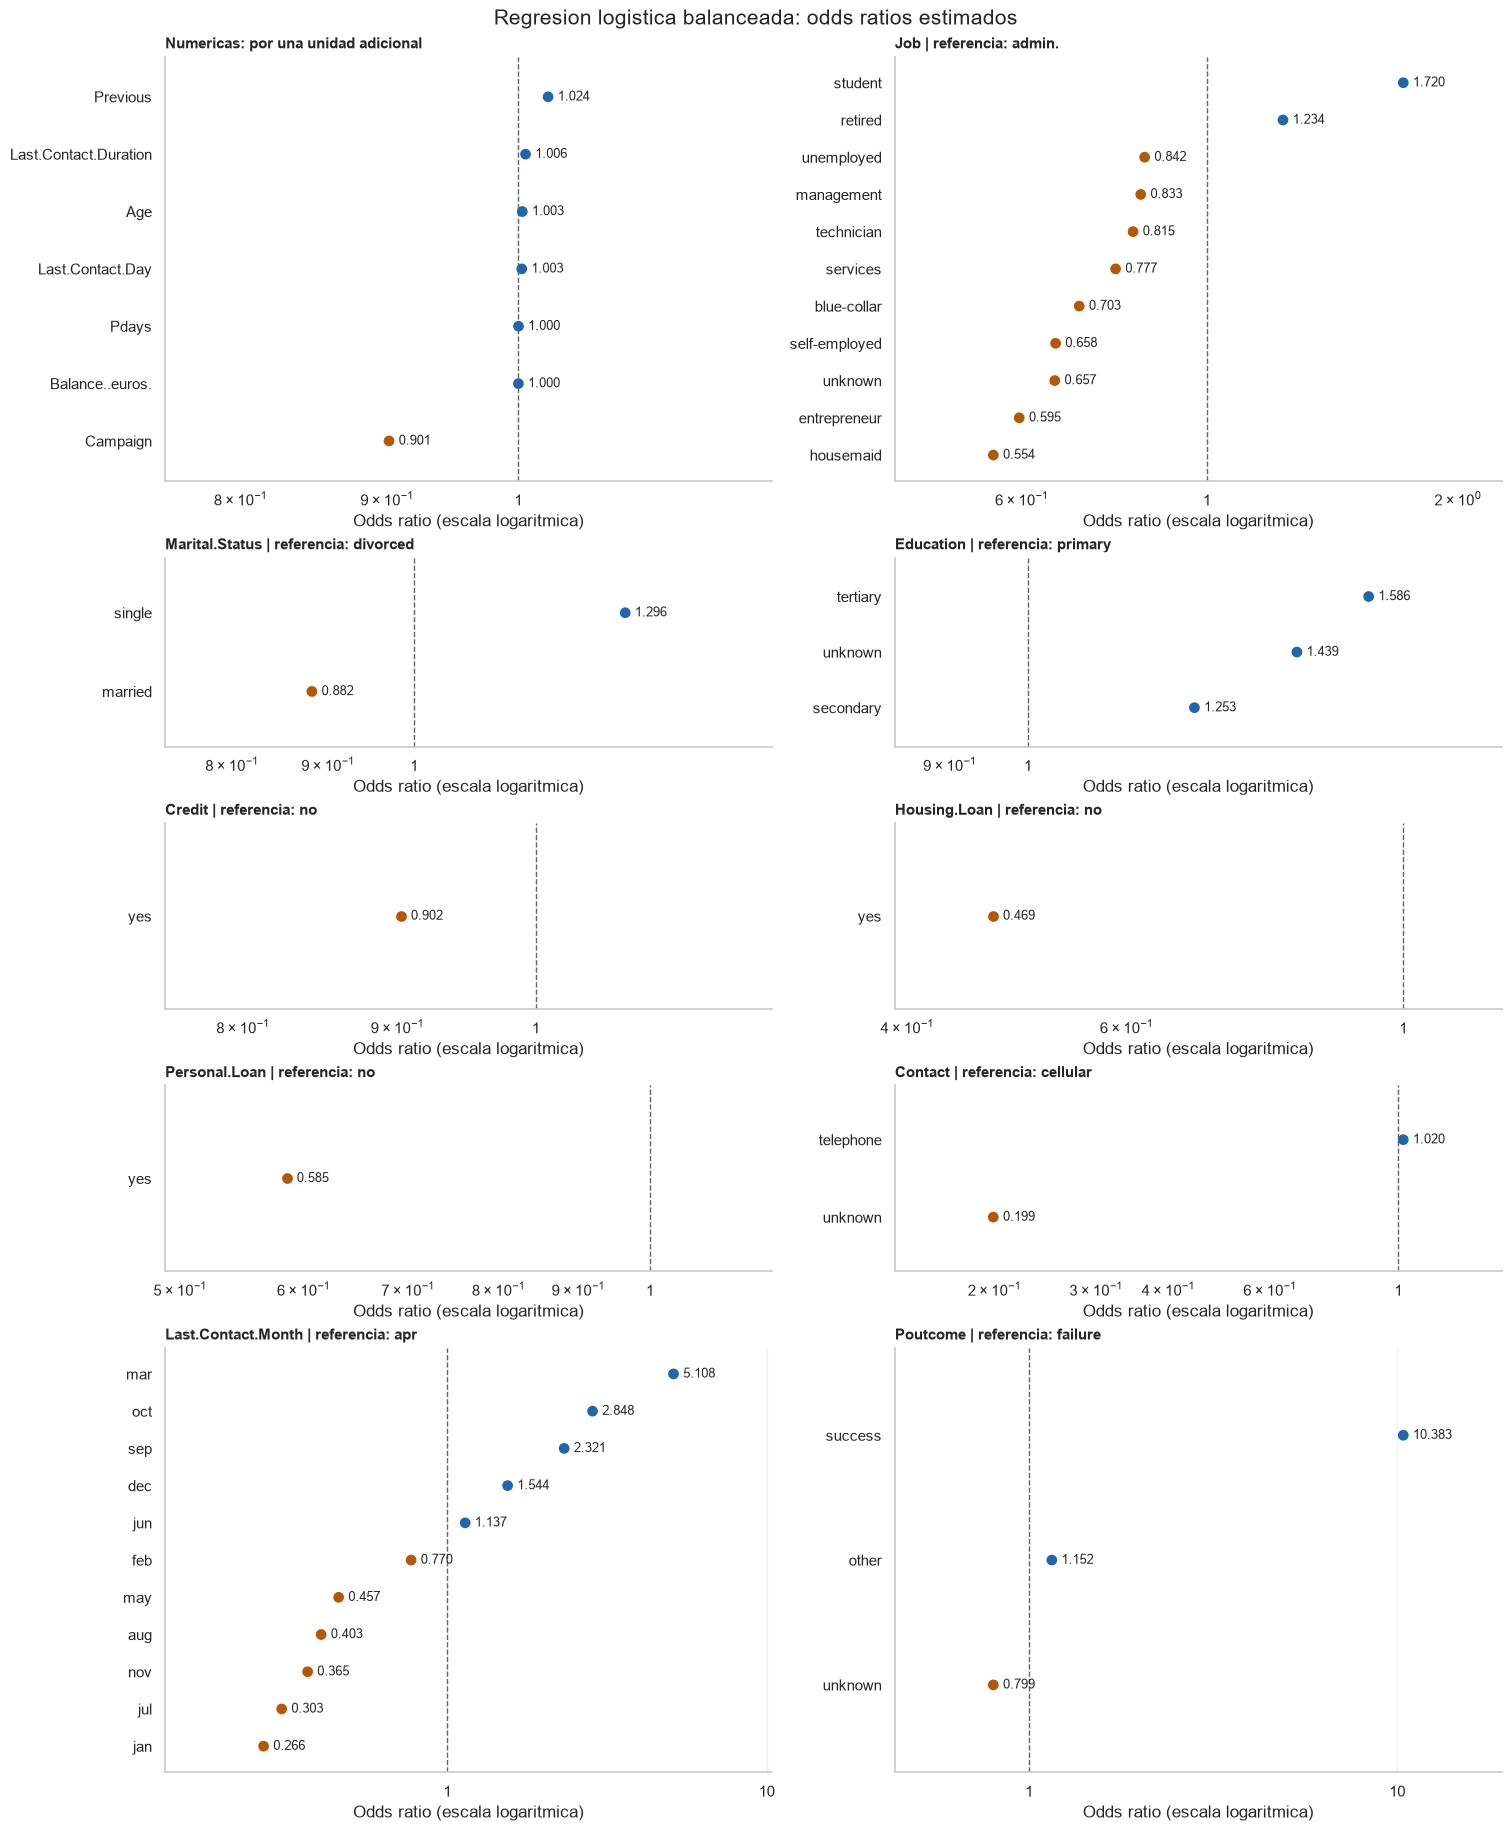

In [10]:
from matplotlib.ticker import FuncFormatter
import math

# Usar los parametros ya estimados; no se reajusta el modelo.
paneles_or = []
numericos_or = tabla_parametros_originales[
    tabla_parametros_originales['Termino'].isin(numeric_cols)
].copy()
if not numericos_or.empty:
    paneles_or.append(('Numericas: por una unidad adicional', numericos_or))
for referencia_or in referencias_categoricas:
    variable_or = referencia_or['Variable']
    grupo_or = tabla_parametros_originales[
        tabla_parametros_originales['Termino'].str.startswith(variable_or + '=')
    ].copy()
    if not grupo_or.empty:
        grupo_or['Termino'] = grupo_or['Termino'].str.slice(len(variable_or) + 1)
        paneles_or.append((f"{variable_or} | referencia: {referencia_or['Referencia']}", grupo_or))

columnas_or = 2
filas_or = math.ceil(len(paneles_or) / columnas_or)
alturas_or = [max(2.4, 0.38 * max(len(datos) for _, datos in paneles_or[i:i + columnas_or]) + 1.3)
              for i in range(0, len(paneles_or), columnas_or)]
fig_or, axes_or = plt.subplots(
    filas_or, columnas_or, figsize=(15, sum(alturas_or)), squeeze=False,
    gridspec_kw={'height_ratios': alturas_or}, layout='constrained'
)
for ax_or, (titulo_or, datos_or) in zip(axes_or.flat, paneles_or):
    datos_or = datos_or.sort_values('Odds ratio')
    valores_or = datos_or['Odds ratio'].to_numpy()
    posiciones_or = np.arange(len(datos_or))
    colores_or = np.where(valores_or >= 1, '#2166ac', '#b35806')
    ax_or.axvline(1, color='#666666', linestyle='--', linewidth=1)
    ax_or.scatter(valores_or, posiciones_or, c=colores_or, s=45, zorder=3)
    ax_or.set_yticks(posiciones_or, labels=datos_or['Termino'])
    ax_or.set_xscale('log')
    # Incluir siempre OR=1 y dejar espacio para las etiquetas numericas.
    inferior_or = min(float(valores_or.min()), 1.0)
    superior_or = max(float(valores_or.max()), 1.0)
    margen_or = max(np.log(superior_or / inferior_or) * 0.24, 0.18)
    ax_or.set_xlim(inferior_or * np.exp(-margen_or), superior_or * np.exp(margen_or))
    for valor_or, posicion_or in zip(valores_or, posiciones_or):
        ax_or.annotate(f'{valor_or:.3f}', (valor_or, posicion_or),
                       xytext=(7, 0), textcoords='offset points', va='center', fontsize=9)
    ax_or.xaxis.set_major_formatter(FuncFormatter(lambda valor, _: f'{valor:g}'))
    ax_or.set_title(titulo_or, loc='left', fontsize=11, fontweight='bold')
    ax_or.set_xlabel('Odds ratio (escala logaritmica)')
    ax_or.grid(axis='x', alpha=0.25)
    ax_or.grid(axis='y', visible=False)
    ax_or.set_ylim(-0.7, len(datos_or) - 0.3)
    ax_or.spines[['top', 'right']].set_visible(False)
for ax_or in list(axes_or.flat)[len(paneles_or):]:
    ax_or.set_visible(False)
fig_or.suptitle('Regresion logistica balanceada: odds ratios estimados', fontsize=15)
plt.show()


**Resumen:**
Para esta sección se estimaron los parámetros de la regresión logística balanceada con las 31.648 observaciones de entrenamiento. El ajuste convergió en 6 iteraciones y produjo 51 coeficientes y un intercepto, mediante log-verosimilitud ponderada con penalización L2. Se expresaron los efectos numéricos en unidades originales y los efectos categóricos frente a sus referencias, con sus correspondientes odds ratios. Por ultimo, se verificó que la ecuación reconstruida reproduce las probabilidades del pipeline. Esta comprobación valida el cálculo de los parámetros; la capacidad predictiva fuera del ajuste se sustenta en la validación cruzada de la sección 1.


# 3. Interpretación de los parámetros del modelo

## 3.1 Cómo se leen los parámetros de una regresión logística

El modelo de la sección 2 expresa el logaritmo de los odds de suscripción como una combinación lineal de las variables:

$$\log\left(\frac{p}{1-p}\right)=\beta_0+\beta_1x_1+\dots+\beta_kx_k .$$

Aquí $p$ es la probabilidad de que el cliente adquiera el depósito y $p/(1-p)$ son sus odds, de esta ecuación salen las reglas de lectura usadas en esta sección:

* **Coeficiente $\beta_j$.** Es el cambio en el logaritmo de los odds cuando $x_j$ aumenta una unidad y las demás variables permanecen constantes. El signo indica la dirección: positivo aumenta los odds y negativo los reduce.
* **Odds ratio $OR=e^{\beta_j}$.** Al aumentar $x_j$ en una unidad, los odds de suscripción se multiplican por $e^{\beta_j}$. El cambio porcentual de los odds es $100\,(e^{\beta_j}-1)$, si se aumenta $x_j$ en $c$ unidades el odds ratio es $e^{c\,\beta_j}$.
* **Unidades con sentido práctico.** Un segundo de llamada o un euro de saldo son unidades demasiado pequeñas para interpretarse por eso se reporta el OR por 1 minuto de llamada, 1.000 euros de saldo, 10 años de edad, 30 días desde el contacto anterior y 10 días del mes. Campaign y Previous se mantienen en un contacto.
* **Variables categóricas.** $e^{\beta}$ compara los odds de un nivel con los de la categoría de referencia con las demás variables fijas, se conservan las referencias de la sección 2 (primer nivel alfabético): `admin.`, `divorced`, `primary`, `no`, `cellular`, `apr` y `failure`. La comparación entre dos niveles cualesquiera es la diferencia de sus coeficientes.
* **Odds ratio no es lo mismo que cambio en la probabilidad.** Con $p=\text{odds}/(1+\text{odds})$, un mismo OR produce cambios de probabilidad distintos según el perfil de partida. Esto se ilustra en la sección 3.7.

**Dos precauciones propias de este modelo.**

1. **Pesos de clase.** La ponderación `balanced` multiplica por $w_1/w_0\approx7{,}56$ el peso de cada suscriptor, así que los odds ratios conservan su lectura pero el intercepto queda desplazado y las probabilidades que entrega el modelo están infladas respecto de la tasa real del 11,7%. Por lo que en la sección 3.7 se corrige este desplazamiento antes de hablar de probabilidades.
2. **Sin inferencia directa.** El estimador penalizado de scikit-learn no reporta errores estándar, como respaldo se ajusta el modelo logístico clásico visto en clase `glm(..., family = binomial)`, con las mismas variables y referencias (sección 3.2). 
Los p-valores, intervalos y pruebas de razón de verosimilitud provienen de ese modelo.

Todas las relaciones son asociaciones condicionadas a las variables incluidas en el modelo que provienen de una campaña observada y no de un experimento, por lo que no demuestran causalidad.

## 3.2 Respaldo inferencial: modelo logístico clásico (glm binomial)

Se ajusta por máxima verosimilitud, sin pesos ni penalización, un modelo con las mismas 16 variables, las numéricas en unidades originales y las mismas categorías de referencia, a partir de él se calcula:

* **Significancia global** con la prueba de razón de verosimilitud (LR) frente al modelo solo con intercepto: $LR = D_0 - D$, donde $D_0$ es la devianza nula y $D$ la residual, con distribución $\chi^2$ de $k$ grados de libertad bajo $H_0:\beta_1=\dots=\beta_k=0$.
* **Significancia de cada variable** con la prueba LR, comparando el modelo completo con el modelo que excluye la variable, para una variable categórica la prueba evalúa todas sus indicadoras a la vez, por ejemplo $H_0$: los 11 coeficientes de `Job` son cero.
* **Intervalos al 95 % para los odds ratios** (de Wald): $\exp\big(\hat\beta_j \pm 1{,}96\,\mathrm{EE}(\hat\beta_j)\big)$. Si el intervalo no contiene 1 el efecto es significativo al 5%.

Antes de interpretar se revisa la regla de unos 10 eventos por parámetro y la multicolinealidad (VIF) como en los módulos 4 y 7.

In [11]:
import statsmodels.api as sm
from pathlib import Path
from scipy.stats import chi2, norm
from statsmodels.stats.outliers_influence import variance_inflation_factor

ruta_anexos = Path('analisis_anexos')
ruta_anexos.mkdir(exist_ok=True)

def matriz_referencia(datos):
    # Numericas en unidades originales e indicadoras sin la categoria de referencia de la sección 2
    partes = [datos[numeric_cols].astype(float)]
    for columna, niveles in zip(categorical_cols, codificador_final.categories_):
        categoria = pd.Categorical(datos[columna], categories=niveles)
        indicadoras = pd.get_dummies(categoria, prefix=columna, prefix_sep='=',
                                     drop_first=True, dtype=float)
        indicadoras.index = datos.index
        partes.append(indicadoras)
    return sm.add_constant(pd.concat(partes, axis=1), has_constant='add')

def formato_p(valor):
    if pd.isna(valor):
        return '-'
    return '< 0.001' if valor < 0.001 else f'{valor:.3f}'

diseno_glm = matriz_referencia(X)
terminos = tabla_parametros_originales['Termino'].tolist()
assert diseno_glm.columns[1:].tolist() == terminos, 'Los terminos no coinciden con la seccion 2'

glm_clasico = sm.GLM(y, diseno_glm, family=sm.families.Binomial()).fit()
if not glm_clasico.converged:
    raise RuntimeError('El glm clasico no convergio.')

parametros_glm = len(glm_clasico.params)
eventos = int(y.sum())
lr_global = glm_clasico.null_deviance - glm_clasico.deviance
gl_global = parametros_glm - 1
vif_glm = pd.Series(
    [variance_inflation_factor(diseno_glm.to_numpy(), i) for i in range(1, parametros_glm)],
    index=terminos,
)
display(pd.DataFrame({
    'Medida': ['Observaciones', 'Suscripciones (eventos)', 'Parametros (incluye intercepto)',
               'Eventos por parametro', 'Devianza nula', 'Devianza residual', 'AIC',
               f'LR global (gl = {gl_global})', 'p-valor LR global', 'VIF maximo'],
    'Valor': [f'{len(y):,}', f'{eventos:,}', f'{parametros_glm}', f'{eventos / gl_global:.1f}',
              f'{glm_clasico.null_deviance:,.2f}', f'{glm_clasico.deviance:,.2f}',
              f'{glm_clasico.aic:,.2f}', f'{lr_global:,.2f}', formato_p(chi2.sf(lr_global, gl_global)),
              f'{vif_glm.max():.2f} ({vif_glm.idxmax()})'],
}))

# Prueba de razon de verosimilitud por variable
filas_lrt = []
for variable in numeric_cols + categorical_cols:
    columnas = ([variable] if variable in numeric_cols
                else [c for c in diseno_glm.columns if c.startswith(variable + '=')])
    reducido = sm.GLM(y, diseno_glm.drop(columns=columnas), family=sm.families.Binomial()).fit()
    estadistico = reducido.deviance - glm_clasico.deviance
    filas_lrt.append({'Variable': variable, 'gl': len(columnas),
                      'Chi-cuadrado LR': estadistico, 'p-valor': chi2.sf(estadistico, len(columnas))})
prueba_lrt = (pd.DataFrame(filas_lrt)
              .sort_values('Chi-cuadrado LR', ascending=False).reset_index(drop=True))
prueba_lrt['Decision al 5 %'] = np.where(prueba_lrt['p-valor'] < 0.05,
                                         'Se rechaza H0', 'No se rechaza H0')
display(prueba_lrt.assign(**{'p-valor': prueba_lrt['p-valor'].map(formato_p)}).round(2))

,Medida,Valor
0,Observaciones,"31,648"
1,Suscripciones (eventos),"3,697"
2,Parametros (incluye intercepto),43
3,Eventos por parametro,88.0
4,Devianza nula,"22,820.31"
5,Devianza residual,"15,177.45"
6,AIC,"15,263.45"
7,LR global (gl = 42),"7,642.86"
8,p-valor LR global,< 0.001
9,VIF maximo,6.15 (Poutcome=unknown)


,Variable,gl,Chi-cuadrado LR,p-valor,Decision al 5 %
0,Last.Contact.Duration,1,3842.11,< 0.001,Se rechaza H0
1,Poutcome,3,797.86,< 0.001,Se rechaza H0
2,Last.Contact.Month,11,660.62,< 0.001,Se rechaza H0
3,Contact,2,384.38,< 0.001,Se rechaza H0
4,Housing.Loan,1,173.91,< 0.001,Se rechaza H0
5,Campaign,1,79.85,< 0.001,Se rechaza H0
6,Job,11,61.21,< 0.001,Se rechaza H0
7,Personal.Loan,1,36.32,< 0.001,Se rechaza H0
8,Marital.Status,2,34.55,< 0.001,Se rechaza H0
9,Education,3,16.34,< 0.001,Se rechaza H0


**Qué se observa:**

* **Información suficiente.** El glm usa 31.648 clientes y 3.697 suscripciones para estimar 43 parámetros: 88 eventos por parámetro, muy por encima de la regla orientativa de 10, dado que el ajuste convergió sin avisos de separación.
* **Significancia global.** $LR = 22.820{,}31 - 15.177{,}45 = 7.642{,}86$ con 42 gl y p < 0,001: se rechaza $H_0$ y al menos una variable se asocia con la suscripción, la devianza baja un 33,5 % frente al modelo con solo intercepto (pseudo-$R^2$ de McFadden ≈ 0,335).
* **Multicolinealidad.** El VIF máximo es 6,15 por debajo de 10. Los valores más altos vienen de la relación entre `Poutcome`, `Pdays` y `Previous` pero no impiden interpretar cada coeficiente.
* **Pruebas por variable.** **12 de las 16 variables son significativas al 5%.** Las cuatro que no lo son:
  * `Age` (p = 0,454).
  * `Pdays` (p = 0,792).
  * `Previous` (p = 0,172).
  * `Credit` (p = 0,966), con solo 583 clientes en incumplimiento.

  Esto no quiere decir que no tengan relación bruta con la suscripción, sino que no agregan información una vez se controla el resto, por ejemplo el historial de contactos que miden `Pdays` y `Previous` ya está en `Poutcome`.
* `Last.Contact.Day` (p = 0,012) y `Balance..euros.` (p = 0,014) son significativas, pero sus $\chi^2$ son pequeños (6,4 y 6,1), con esta muestra se detectan efectos de magnitud baja.
* Las variables no significativas se conservan porque el modelo se eligió por capacidad predictiva, sus odds ratios se leen como "sin evidencia de asociación una vez controladas las demás variables".

## 3.3 Variables numéricas: odds ratios en unidades con sentido práctico

Para cada variable numérica se reporta el OR del modelo elegido por el incremento indicado y el cambio porcentual en los odds, al lado aparecen el OR, el intervalo al 95% y el p-valor del glm clásico para el mismo incremento.

La última columna OR por 1 DE, es el odds ratio por un aumento de una desviación estándar, corresponde al coeficiente que estimó el modelo sobre las variables estandarizadas de la sección 2, como no depende de las unidades permite comparar la magnitud de los efectos entre variables numéricas (coeficientes estandarizados).

`Pdays` vale −1 cuando el cliente no fue contactado antes y en este conjunto eso ocurre exactamente cuando `Previous = 0` y `Poutcome = unknown` (salvo 2 registros), el efecto de no haber sido contactado ya lo recoge `Poutcome = unknown` y por eso el OR de `Pdays` describe, en la práctica, el efecto de los días transcurridos entre los clientes contactados previamente.

In [12]:
unidades_interpretacion = {
    'Age': (10, '+10 años'),
    'Balance..euros.': (1000, '+1.000 euros'),
    'Last.Contact.Day': (10, '+10 días del mes'),
    'Last.Contact.Duration': (60, '+1 minuto'),
    'Campaign': (1, '+1 contacto'),
    'Pdays': (30, '+30 días'),
    'Previous': (1, '+1 contacto previo'),
}
escala_terminos = pd.Series(1.0, index=terminos)
for variable in numeric_cols:
    escala_terminos[variable] = unidades_interpretacion.get(variable, (1, ''))[0]

beta_elegido = tabla_parametros_originales.set_index('Termino')['Coeficiente']
beta_glm = glm_clasico.params.drop('const')
ee_glm = glm_clasico.bse.drop('const')
z_critico = norm.ppf(0.975)

# Odds ratios de ambos modelos en la misma escala
odds_comparados = pd.DataFrame({
    'OR modelo elegido': np.exp(escala_terminos * beta_elegido),
    'OR glm': np.exp(escala_terminos * beta_glm),
    'IC 95 % inferior': np.exp(escala_terminos * (beta_glm - z_critico * ee_glm)),
    'IC 95 % superior': np.exp(escala_terminos * (beta_glm + z_critico * ee_glm)),
    'p-valor': glm_clasico.pvalues.drop('const'),
})
odds_comparados.insert(1, 'Cambio en los odds (%)', 100 * (odds_comparados['OR modelo elegido'] - 1))

tabla_numericas = odds_comparados.loc[numeric_cols].copy()
tabla_numericas.insert(0, 'Incremento', [unidades_interpretacion[v][1] for v in numeric_cols])
tabla_numericas['OR por 1 DE'] = np.exp(beta_transformado[:cantidad_numericas])
tabla_numericas['1 DE equivale a'] = escalador_final.scale_
display(tabla_numericas.assign(**{'p-valor': tabla_numericas['p-valor'].map(formato_p)}).round(3))

,Incremento,OR modelo elegido,Cambio en los odds (%),OR glm,IC 95 % inferior,IC 95 % superior,p-valor,OR por 1 DE,1 DE equivale a
Age,+10 años,1.032,3.227,1.020,0.969,1.074,0.453,1.034,10.616
Balance..euros.,+1.000 euros,1.023,2.294,1.015,1.003,1.027,0.012,1.073,3089.302
Last.Contact.Day,+10 días del mes,1.028,2.765,1.078,1.017,1.143,0.012,1.023,8.327
Last.Contact.Duration,+1 minuto,1.413,41.311,1.285,1.273,1.296,< 0.001,4.350,255.099
Campaign,+1 contacto,0.901,-9.878,0.904,0.882,0.926,< 0.001,0.723,3.116
Pdays,+30 días,1.003,0.323,1.003,0.982,1.025,0.792,1.011,99.753
Previous,+1 contacto previo,1.024,2.421,1.009,0.996,1.022,0.169,1.061,2.476


**Qué se observa:**

* **Duración de la llamada.** Cada minuto adicional multiplica los odds de suscripción por **1,413 (+41,3 %)** en el modelo elegido. El glm da 1,285, con IC 95 % de 1,273 a 1,296 y p < 0,001. Es el efecto numérico más fuerte: por una desviación estándar (255 s, unos 4,3 minutos) el OR es **4,350**. Es una asociación, porque los clientes interesados tienden a conversar más; en la sección 3.8 se analiza qué pasa sin esta variable.
* **Número de contactos en la campaña.** Cada contacto adicional **reduce los odds un 9,9 %** (OR = 0,901; glm 0,904, con IC de 0,882 a 0,926). Con tres contactos más, los odds quedan multiplicados por $0{,}901^3 \approx 0{,}73$. Insistir con más llamadas no se asocia con más suscripciones: los clientes que requieren muchos intentos son los menos propensos. Por desviación estándar (3,1 contactos) el OR es 0,723, el segundo efecto numérico más fuerte.
* **Saldo.** 1.000 euros más se asocian con odds **2,3 % mayores** (OR = 1,023; glm 1,015, con IC de 1,003 a 1,027 y p = 0,012). El efecto es positivo pero pequeño: incluso una desviación estándar (3.089 euros) solo da OR = 1,073.
* **Día del mes.** 10 días más tarde en el mes dan OR = 1,028 (glm 1,078, con IC de 1,017 a 1,143 y p = 0,012). Es un efecto pequeño, su magnitud difiere entre modelos y cambia de signo en la sección 3.8. No tiene una lectura de negocio clara.
* **Sin evidencia de efecto:** edad (OR = 1,032 por 10 años, con IC del glm de 0,969 a 1,074), `Pdays` (1,003 por 30 días; de 0,982 a 1,025) y `Previous` (1,024 por contacto; de 0,996 a 1,022). Sus intervalos contienen 1. En `Previous`, el OR del modelo elegido queda apenas por encima del límite superior del glm, pero en la práctica sigue siendo cercano a 1.

## 3.4 Variables categóricas: odds ratios frente a la categoría de referencia

Cada fila compara los odds de un nivel con los de la referencia de su variable (OR = 1). Se agregan el número de clientes y la **tasa observada de suscripción** de cada nivel, porque ayudan a reconocer niveles con pocos casos y a distinguir el efecto **ajustado** (el OR, con las demás variables constantes) de la diferencia **bruta** entre grupos.

In [13]:
filas_categoricas = []
for referencia in referencias_categoricas:
    variable, nivel_ref = referencia['Variable'], referencia['Referencia']
    resumen = y.groupby(X[variable]).agg(['size', 'mean'])
    filas_categoricas.append({
        'Variable': variable, 'Nivel': f'{nivel_ref} (ref.)',
        'Clientes': int(resumen.loc[nivel_ref, 'size']),
        'Tasa observada (%)': 100 * resumen.loc[nivel_ref, 'mean'],
        'OR modelo elegido': 1.0, 'Cambio en los odds (%)': 0.0, 'OR glm': 1.0,
        'IC 95 % inferior': np.nan, 'IC 95 % superior': np.nan, 'p-valor': np.nan,
    })
    for termino in [t for t in terminos if t.startswith(variable + '=')]:
        nivel = termino.split('=', 1)[1]
        filas_categoricas.append({
            'Variable': variable, 'Nivel': nivel,
            'Clientes': int(resumen.loc[nivel, 'size']),
            'Tasa observada (%)': 100 * resumen.loc[nivel, 'mean'],
            **odds_comparados.loc[termino].to_dict(),
        })
tabla_categoricas = pd.DataFrame(filas_categoricas)
with pd.option_context('display.max_rows', 100):
    display(tabla_categoricas.assign(**{'p-valor': tabla_categoricas['p-valor'].map(formato_p)}).round(3))

,Variable,Nivel,Clientes,Tasa observada (%),OR modelo elegido,Cambio en los odds (%),OR glm,IC 95 % inferior,IC 95 % superior,p-valor
0,Job,admin. (ref.),3592,11.943,1.000,0.000,1.000,NaN,NaN,-
1,Job,blue-collar,6763,7.482,0.703,-29.736,0.775,0.653,0.919,0.003
2,Job,entrepreneur,1067,7.779,0.595,-40.468,0.641,0.474,0.865,0.004
3,Job,housemaid,868,7.834,0.554,-44.583,0.526,0.377,0.734,< 0.001
4,Job,management,6594,13.891,0.833,-16.714,0.906,0.763,1.077,0.263
5,Job,retired,1604,21.696,1.234,23.383,1.179,0.936,1.485,0.162
6,Job,self-employed,1125,11.644,0.658,-34.172,0.764,0.588,0.993,0.044
7,Job,services,2951,9.217,0.777,-22.300,0.858,0.707,1.043,0.124
8,Job,student,671,28.614,1.720,72.021,1.492,1.157,1.923,0.002
9,Job,technician,5278,10.894,0.815,-18.463,0.869,0.739,1.022,0.090


**Qué se observa:**

* **Resultado de la campaña anterior:** es el efecto categórico más fuerte, un éxito previo multiplica los odds por 10,38 frente a un fracaso (glm 9,40; IC de 7,77 a 11,38) y por 12,99 frente a un cliente nunca contactado. `other` y `unknown` no se diferencian de `failure` (p = 0,158 y 0,399), lo que importa es haber aceptado antes.
* **Préstamos:** el de vivienda reduce los odds un 53,1% (OR = 0,469) y el personal un 41,5% (OR = 0,585) lo que es coherente con una menor liquidez para ahorrar, el incumplimiento de crédito no muestra efecto (p = 0,966).
* **Medio de contacto:** el canal `unknown` reduce los odds un 80,1% frente al celular (OR = 0,199) mientras que teléfono y celular no se diferencian (p = 0,418). Como `unknown` es un canal no registrado, el efecto refleja más una etapa de la campaña que el canal en sí.
* **Mes (referencia abril):** marzo (5,11), octubre (2,85) y septiembre (2,32) aumentan los odds, y enero (0,27), julio (0,30), noviembre (0,37), agosto (0,40) y mayo (0,46) los reducen. Los meses con OR alto son los de menos llamadas (marzo, septiembre, octubre y diciembre suman el 4,4% de los contactos) mientras que mayo concentra el 30,3% con una tasa de 6,9% por lo que el patrón refleja la intensidad de la campaña más que el calendario.
* **Ocupación (referencia `admin.`):** los estudiantes tienen odds 72% mayores (OR = 1,720) y `housemaid` (0,554), `entrepreneur` (0,595), `self-employed` (0,658) y `blue-collar` (0,703) entre 30% y 45% menores. Los jubilados tienen una tasa bruta alta (21,7%) pero su OR ajustado no es significativo (p = 0,162).
* **Educación y estado civil:** frente a primaria, la educación terciaria aumenta los odds un 58,6% y la secundaria un 25,3%. Frente a los divorciados, los solteros tienen odds 29,6% mayores y los casados 11,8% menores.

## 3.5 Comparación gráfica de los odds ratios

El rombo rojo es el OR del modelo elegido y el círculo con su segmento es el OR y el IC 95% del glm clásico: azul si el intervalo excluye 1 y gris si lo incluye. El eje es logarítmico así que OR = 2 y OR = 0,5 quedan a la misma distancia de 1.

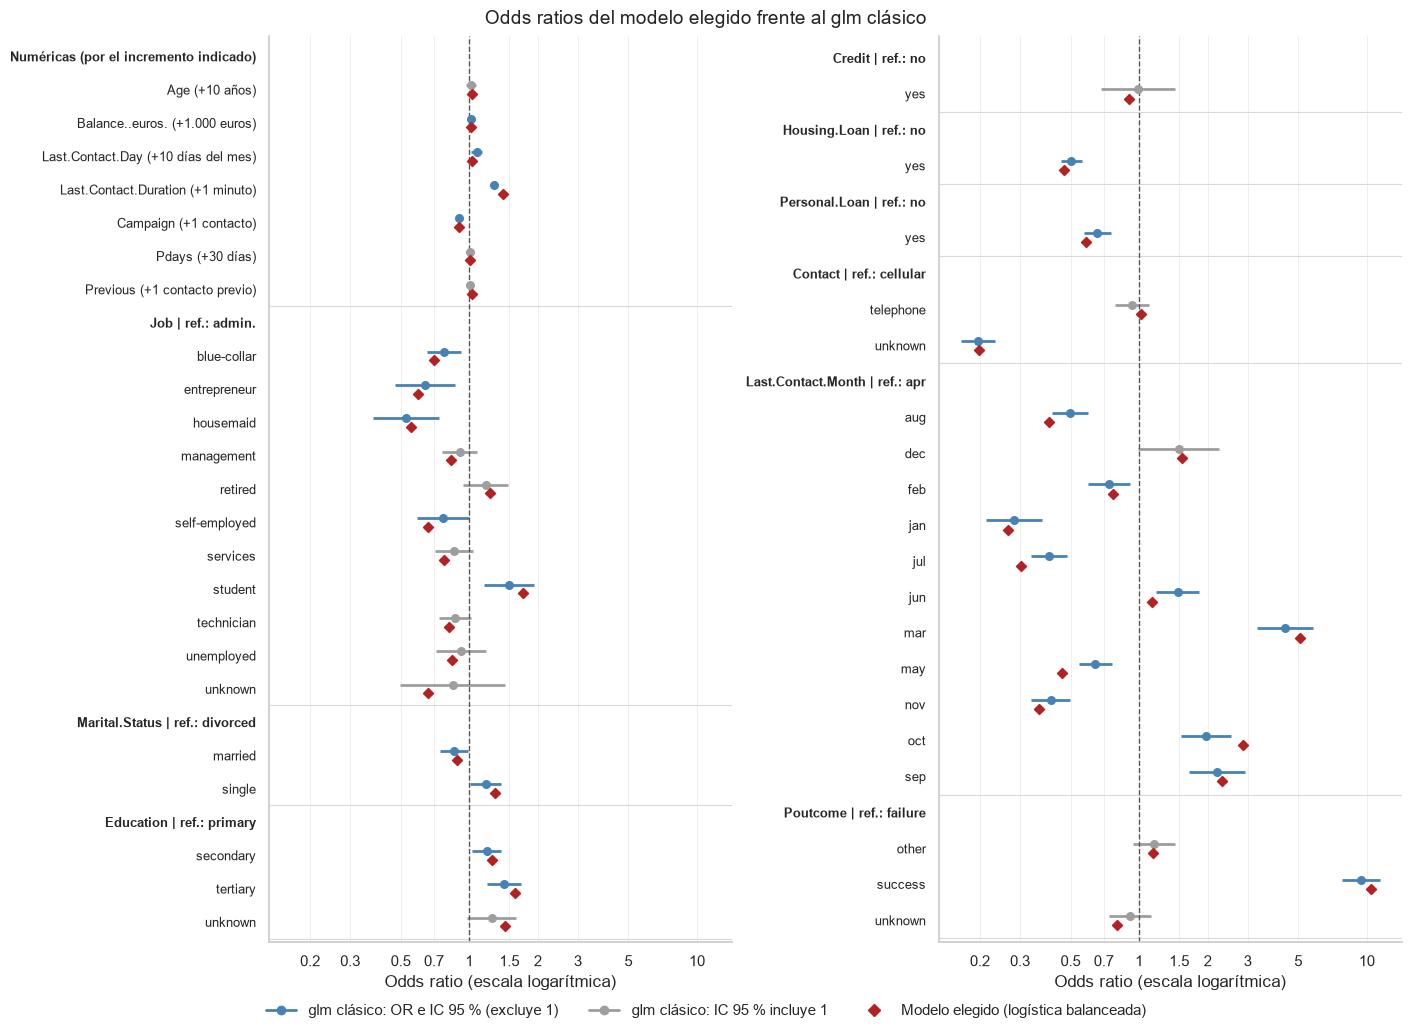

Terminos con el mismo signo en ambos modelos: 41 de 42
Terminos con signo distinto: Contact=telephone
Correlacion entre coeficientes de ambos modelos: 0.9868
OR del modelo elegido fuera del IC 95 % del glm: 7 de 42
   Last.Contact.Duration, Previous, Last.Contact.Month=aug, Last.Contact.Month=jul, Last.Contact.Month=jun, Last.Contact.Month=may, Last.Contact.Month=oct


Diferencia maxima |beta elegido - beta glm ponderado sin penalizacion|: 0.0259 (Last.Contact.Month=mar)
Diferencia maxima |beta elegido - beta glm clasico|: 0.3714 (Last.Contact.Month=oct)


In [ ]:
from matplotlib.lines import Line2D

color_significativo, color_no_significativo, color_elegido = 'steelblue', '#9e9e9e', 'firebrick'
grupos_or = [('Numéricas (por el incremento indicado)', [(v, f'{v} ({unidades_interpretacion[v][1]})')
                                                         for v in numeric_cols])]
for referencia in referencias_categoricas:
    variable = referencia['Variable']
    grupos_or.append((f"{variable} | ref.: {referencia['Referencia']}",
                      [(t, t.split('=', 1)[1]) for t in terminos if t.startswith(variable + '=')]))

# Repartir los grupos en dos columnas con un numero parecido de filas
filas_por_grupo = np.array([len(items) + 1 for _, items in grupos_or])
corte = int(np.searchsorted(np.cumsum(filas_por_grupo), filas_por_grupo.sum() / 2)) + 1
columnas_grafico = [grupos_or[:corte], grupos_or[corte:]]
limite_inferior = odds_comparados[['OR modelo elegido', 'IC 95% inferior']].min().min() * 0.8
limite_superior = odds_comparados[['OR modelo elegido', 'IC 95% superior']].max().max() * 1.25
filas_max = max(sum(len(items) + 1 for _, items in col) for col in columnas_grafico)

fig_forest, ejes_forest = plt.subplots(1, 2, figsize=(14, 0.32 * filas_max + 1.6), layout='constrained')
for eje, grupos in zip(ejes_forest, columnas_grafico):
    posicion, marcas, etiquetas = 0, [], []
    for titulo, items in grupos:
        marcas.append(posicion)
        etiquetas.append(titulo)
        posicion -= 1
        for termino, etiqueta in items:
            fila = odds_comparados.loc[termino]
            excluye_uno = fila['IC 95 % inferior'] > 1 or fila['IC 95 % superior'] < 1
            color = color_significativo if excluye_uno else color_no_significativo
            eje.hlines(posicion + 0.13, fila['IC 95 % inferior'], fila['IC 95 % superior'],
                       color=color, linewidth=2)
            eje.scatter(fila['OR glm'], posicion + 0.13, color=color, s=30, zorder=3)
            eje.scatter(fila['OR modelo elegido'], posicion - 0.13, color=color_elegido,
                        marker='D', s=26, zorder=4)
            marcas.append(posicion)
            etiquetas.append('   ' + etiqueta)
            posicion -= 1
        eje.axhline(posicion + 0.5, color='#d9d9d9', linewidth=0.8)
    eje.axvline(1, color='#555555', linestyle='--', linewidth=1)
    eje.set_xscale('log')
    eje.set_xlim(limite_inferior, limite_superior)
    eje.set_xticks([t for t in [0.2, 0.3, 0.5, 0.7, 1, 1.5, 2, 3, 5, 10]
                    if limite_inferior <= t <= limite_superior])
    eje.xaxis.set_minor_locator(plt.NullLocator())
    eje.xaxis.set_major_formatter(FuncFormatter(lambda valor, _: f'{valor:g}'))
    eje.set_yticks(marcas, labels=etiquetas, fontsize=9)
    for texto in eje.get_yticklabels():
        if not texto.get_text().startswith('   '):
            texto.set_fontweight('bold')
    eje.set_ylim(posicion + 0.4, 0.6)
    eje.set_xlabel('Odds ratio (escala logarítmica)')
    eje.grid(axis='x', color='#ececec', linewidth=0.6)
    eje.grid(axis='y', visible=False)
    eje.spines[['top', 'right']].set_visible(False)
leyenda_forest = [
    Line2D([], [], color=color_significativo, marker='o', linewidth=2,
           label='glm clásico: OR e IC 95 % (excluye 1)'),
    Line2D([], [], color=color_no_significativo, marker='o', linewidth=2,
           label='glm clásico: IC 95 % incluye 1'),
    Line2D([], [], color=color_elegido, marker='D', linestyle='none',
           label='Modelo elegido (logística balanceada)'),
]
fig_forest.legend(handles=leyenda_forest, loc='outside lower center', ncol=3, frameon=False)
fig_forest.suptitle('Odds ratios del modelo elegido frente al glm clásico', fontsize=14)
fig_forest.savefig(ruta_anexos / 'interpretacion_or_modelo_vs_glm.png', dpi=200,
                   bbox_inches='tight', facecolor='white')
plt.show()

coinciden_signo = (np.sign(beta_elegido) == np.sign(beta_glm))
print(f'Terminos con el mismo signo en ambos modelos: {coinciden_signo.sum()} de {len(terminos)}')
print('Terminos con signo distinto:', ', '.join(coinciden_signo.index[~coinciden_signo]) or 'ninguno')
print(f'Correlacion entre coeficientes de ambos modelos: {np.corrcoef(beta_elegido, beta_glm)[0, 1]:.4f}')
fuera_ic = odds_comparados.index[(odds_comparados['OR modelo elegido'] < odds_comparados['IC 95 % inferior'])
                                 | (odds_comparados['OR modelo elegido'] > odds_comparados['IC 95 % superior'])]
print(f'OR del modelo elegido fuera del IC 95 % del glm: {len(fuera_ic)} de {len(terminos)}')
print('  ', ', '.join(fuera_ic))

# Origen de las diferencias: glm con los mismos pesos de clase y sin penalizacion
pesos_observacion = y.map(pesos_clase).to_numpy()
glm_ponderado = sm.GLM(y, diseno_glm, family=sm.families.Binomial(),
                       freq_weights=pesos_observacion).fit()
diferencia_penalizacion = (beta_elegido - glm_ponderado.params.drop('const')).abs()
print(f'Diferencia maxima |beta elegido - beta glm ponderado sin penalizacion|: '
      f'{diferencia_penalizacion.max():.4f} ({diferencia_penalizacion.idxmax()})')
print(f'Diferencia maxima |beta elegido - beta glm clasico|: '
      f'{(beta_elegido - beta_glm).abs().max():.4f} ({(beta_elegido - beta_glm).abs().idxmax()})')

**Qué se observa:**

* El signo coincide en 41 de 42 términos (correlación de 0,9868). El único distinto es `Contact=telephone` cercano a 1 y no significativo en ambos modelos.
* El modelo elegido da OR algo más alejados de 1 (duración 1,413 frente a 1,285, octubre 2,848 frente a 1,965) y 7 de los 42 quedan fuera del IC del glm. La diferencia se debe a los pesos de clase y no a la penalización: un glm con los mismos pesos y sin penalizar reproduce los coeficientes con una diferencia máxima de 0,026.
* La dirección y el orden de los efectos son confiables en ambos modelos y la incertidumbre se toma de los intervalos del glm.

## 3.6 Importancia relativa de las variables

Con más de 31.000 observaciones casi cualquier efecto resulta significativo, por eso se compara también la magnitud del aporte de cada variable con el $\chi^2$ de la prueba LR de la sección 3.2 es decir, cuánto aumenta la devianza al quitarla.

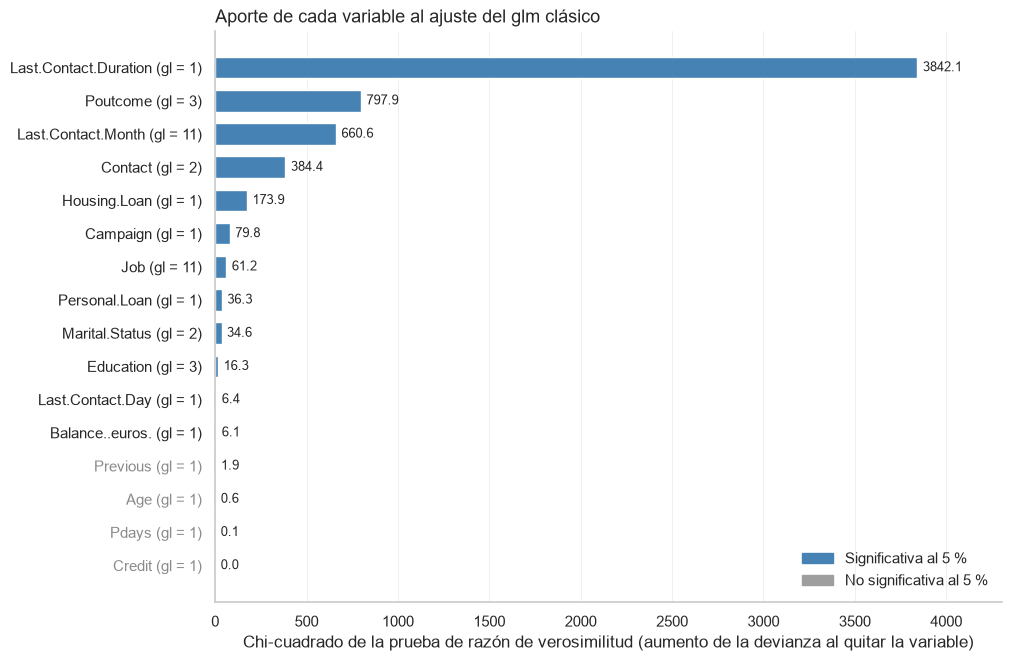

In [15]:
orden_lrt = prueba_lrt.sort_values('Chi-cuadrado LR')
colores_lrt = np.where(orden_lrt['p-valor'] < 0.05, color_significativo, color_no_significativo)
fig_lrt, eje_lrt = plt.subplots(figsize=(10, 6.5), layout='constrained')
eje_lrt.barh([f'{v} (gl = {g})' for v, g in zip(orden_lrt['Variable'], orden_lrt['gl'])],
             orden_lrt['Chi-cuadrado LR'], color=colores_lrt, height=0.65)
for posicion, valor in enumerate(orden_lrt['Chi-cuadrado LR']):
    eje_lrt.annotate(f'{valor:.1f}', (valor, posicion), xytext=(4, 0),
                     textcoords='offset points', va='center', fontsize=9)
for texto, p_valor in zip(eje_lrt.get_yticklabels(), orden_lrt['p-valor']):
    if p_valor >= 0.05:
        texto.set_color('#8a8a8a')
eje_lrt.set_xlabel('Chi-cuadrado de la prueba de razón de verosimilitud (aumento de la devianza al quitar la variable)')
eje_lrt.set_title('Aporte de cada variable al ajuste del glm clásico', loc='left', fontsize=13)
eje_lrt.set_xlim(0, orden_lrt['Chi-cuadrado LR'].max() * 1.12)
eje_lrt.grid(axis='x', color='#ececec', linewidth=0.6)
eje_lrt.grid(axis='y', visible=False)
eje_lrt.spines[['top', 'right']].set_visible(False)
eje_lrt.legend(handles=[
    plt.Rectangle((0, 0), 1, 1, color=color_significativo, label='Significativa al 5 %'),
    plt.Rectangle((0, 0), 1, 1, color=color_no_significativo, label='No significativa al 5 %'),
], loc='lower right', frameon=False)
fig_lrt.savefig(ruta_anexos / 'interpretacion_importancia_lrt.png', dpi=200,
                bbox_inches='tight', facecolor='white')
plt.show()

**Qué se observa:**

* La duración de la llamada domina ($\chi^2$ = 3.842,1, unas 4,8 veces el de `Poutcome`), le siguen el resultado de la campaña anterior (797,9), el mes (660,6), el medio de contacto (384,4), el préstamo de vivienda (173,9) y el número de contactos (79,8).
* Las variables del perfil del cliente aportan menos: ocupación (61,2), préstamo personal (36,3), estado civil (34,6) y educación (16,3).
* La suscripción se explica más por cómo y cuándo se contactó al cliente, y por su historial con el banco, que por su perfil sociodemográfico. Dentro del perfil el préstamo de vivienda es lo más informativo.

## 3.7 De los odds a la probabilidad

Por los pesos de clase el modelo elegido infla las probabilidades, para llevarlas a la escala real se resta $\log(w_1/w_0)$ al logit lo que no cambia los odds ratios ni el AUC:

$$p_{\text{corregida}}=\frac{1}{1+\exp\!\big[-(\hat\eta-\log(w_1/w_0))\big]} .$$

Luego se toma un cliente típico (mediana de cada variable numérica y moda de cada categórica) y se cambia una característica a la vez, para cada cambio se calcula $\text{odds}=p/(1-p)$, se multiplica por el OR y se vuelve a $p=\text{odds}/(1+\text{odds})$. 
En el escenario de éxito previo también se ajustan `Pdays` y `Previous` porque ese cliente necesariamente fue contactado antes, la gráfica muestra cómo cambia la probabilidad con la duración de la llamada para el perfil base y tres variantes.

In [16]:
log_razon_pesos = float(np.log(pesos_clase[1] / pesos_clase[0]))
logit_entrenamiento = modelo_final.decision_function(X)
display(pd.DataFrame({
    'Probabilidad': ['Modelo elegido sin corregir', 'Modelo elegido con intercepto corregido',
                     'glm clasico', 'Tasa observada de suscripcion'],
    'Promedio en entrenamiento (%)': [100 * expit(logit_entrenamiento).mean(),
                                      100 * expit(logit_entrenamiento - log_razon_pesos).mean(),
                                      100 * glm_clasico.fittedvalues.mean(), 100 * y.mean()],
}).round(2))
print(f'log(w1/w0) = log({pesos_clase[1]:.4f} / {pesos_clase[0]:.4f}) = {log_razon_pesos:.4f}')
print(f'Intercepto con categorias de referencia: {intercepto_referencia:.4f} -> corregido: '
      f'{intercepto_referencia - log_razon_pesos:.4f}')

perfil_base = {c: float(X[c].median()) for c in numeric_cols}
perfil_base.update({c: X[c].mode()[0] for c in categorical_cols})
contactados_antes = X[X['Poutcome'] != 'unknown']
escenarios = {
    'Perfil base': {},
    'Sin préstamo de vivienda': {'Housing.Loan': 'no'},
    'Llamada 5 minutos más larga': {'Last.Contact.Duration': perfil_base['Last.Contact.Duration'] + 300},
    'Un contacto más en la campaña': {'Campaign': perfil_base['Campaign'] + 1},
    'Último contacto en marzo': {'Last.Contact.Month': 'mar'},
    'Medio de contacto desconocido': {'Contact': 'unknown'},
    'Educación terciaria': {'Education': 'tertiary'},
    'Éxito en la campaña anterior': {'Poutcome': 'success',
                                     'Pdays': float(contactados_antes['Pdays'].median()),
                                     'Previous': float(contactados_antes['Previous'].median())},
}
datos_escenarios = pd.DataFrame([{**perfil_base, **cambios} for cambios in escenarios.values()],
                                index=list(escenarios))[X.columns]
logit_escenarios = modelo_final.decision_function(datos_escenarios)
probabilidad_corregida = expit(logit_escenarios - log_razon_pesos)
tabla_escenarios = pd.DataFrame({
    'OR frente al perfil base': np.exp(logit_escenarios - logit_escenarios[0]),
    'Prob. sin corregir (%)': 100 * expit(logit_escenarios),
    'Prob. corregida (%)': 100 * probabilidad_corregida,
    'Cambio (puntos porcentuales)': 100 * (probabilidad_corregida - probabilidad_corregida[0]),
    'Prob. glm clasico (%)': 100 * glm_clasico.predict(matriz_referencia(datos_escenarios)).to_numpy(),
}, index=datos_escenarios.index)
print('Perfil base:', {k: (int(v) if isinstance(v, float) else v) for k, v in perfil_base.items()})
display(tabla_escenarios.round(3))

# Ejemplo paso a paso: quitar el prestamo de vivienda.
p_base = probabilidad_corregida[0]
odds_base = p_base / (1 - p_base)
or_vivienda = tabla_escenarios.loc['Sin préstamo de vivienda', 'OR frente al perfil base']
odds_nuevo = odds_base * or_vivienda
print(f'p_base = {p_base:.4f} -> odds_base = {p_base:.4f}/(1 - {p_base:.4f}) = {odds_base:.4f}')
print(f'odds_nuevo = {odds_base:.4f} x {or_vivienda:.4f} = {odds_nuevo:.4f} '
      f'-> p_nuevo = {odds_nuevo:.4f}/(1 + {odds_nuevo:.4f}) = {odds_nuevo / (1 + odds_nuevo):.4f}')

,Probabilidad,Promedio en entrenamiento (%)
0,Modelo elegido sin corregir,30.86
1,Modelo elegido con intercepto corregido,12.16
2,glm clasico,11.68
3,Tasa observada de suscripcion,11.68


log(w1/w0) = log(4.2802 / 0.5661) = 2.0229
Intercepto con categorias de referencia: -0.8579 -> corregido: -2.8809
Perfil base: {'Age': 39, 'Balance..euros.': 452, 'Last.Contact.Day': 16, 'Last.Contact.Duration': 179, 'Campaign': 2, 'Pdays': -1, 'Previous': 0, 'Job': 'blue-collar', 'Marital.Status': 'married', 'Education': 'secondary', 'Credit': 'no', 'Housing.Loan': 'yes', 'Personal.Loan': 'no', 'Contact': 'cellular', 'Last.Contact.Month': 'may', 'Poutcome': 'unknown'}


,OR frente al perfil base,Prob. sin corregir (%),Prob. corregida (%),Cambio (puntos porcentuales),Prob. glm clasico (%)
Perfil base,1.000,13.294,1.988,0.000,3.747
Sin préstamo de vivienda,2.133,24.647,4.147,2.159,7.170
Llamada 5 minutos más larga,5.635,46.350,10.255,8.268,11.989
Un contacto más en la campaña,0.901,12.140,1.795,-0.193,3.400
Último contacto en marzo,11.185,63.166,18.488,16.501,20.929
Medio de contacto desconocido,0.199,2.958,0.402,-1.586,0.758
Educación terciaria,1.266,16.254,2.503,0.515,4.436
Éxito en la campaña anterior,13.913,68.083,22.005,20.018,29.408


p_base = 0.0199 -> odds_base = 0.0199/(1 - 0.0199) = 0.0203
odds_nuevo = 0.0203 x 2.1333 = 0.0433 -> p_nuevo = 0.0433/(1 + 0.0433) = 0.0415


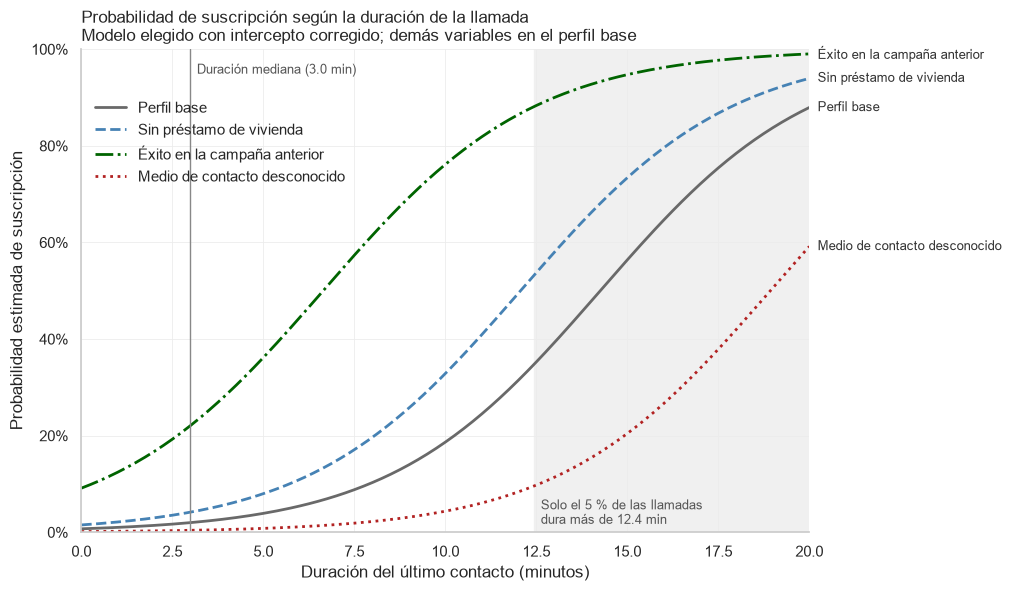

Perfil base                      prob. con la duracion mediana:  1.99 % | alcanza 50 % hacia los 14.3 min
Sin préstamo de vivienda         prob. con la duracion mediana:  4.15 % | alcanza 50 % hacia los 12.1 min
Éxito en la campaña anterior     prob. con la duracion mediana: 22.01 % | alcanza 50 % hacia los  6.6 min
Medio de contacto desconocido    prob. con la duracion mediana:  0.40 % | alcanza 50 % hacia los 18.9 min


In [17]:
from matplotlib.ticker import PercentFormatter

minutos = np.linspace(0, 20, 161)
variantes_curva = [
    ('Perfil base', {}, 'dimgray', '-'),
    ('Sin préstamo de vivienda', {'Housing.Loan': 'no'}, 'steelblue', '--'),
    ('Éxito en la campaña anterior', escenarios['Éxito en la campaña anterior'], 'darkgreen', '-.'),
    ('Medio de contacto desconocido', {'Contact': 'unknown'}, 'firebrick', ':'),
]
fig_prob, eje_prob = plt.subplots(figsize=(10, 5.8), layout='constrained')
percentil_95 = X['Last.Contact.Duration'].quantile(0.95) / 60
eje_prob.axvspan(percentil_95, minutos[-1], color='#f0f0f0', zorder=0)
eje_prob.annotate(f'Solo el 5 % de las llamadas\ndura más de {percentil_95:.1f} min', (percentil_95, 0.01),
                  xytext=(5, 0), textcoords='offset points', fontsize=9, color='#555555', va='bottom')
for etiqueta, cambios, color, estilo in variantes_curva:
    curva = pd.DataFrame([{**perfil_base, **cambios}] * len(minutos))[X.columns]
    curva['Last.Contact.Duration'] = minutos * 60
    probabilidades = expit(modelo_final.decision_function(curva) - log_razon_pesos)
    eje_prob.plot(minutos, probabilidades, color=color, linestyle=estilo, linewidth=2, label=etiqueta)
    eje_prob.annotate(etiqueta, (minutos[-1], probabilidades[-1]), xytext=(6, 0),
                      textcoords='offset points', va='center', fontsize=9, color='#333333')
mediana_minutos = perfil_base['Last.Contact.Duration'] / 60
eje_prob.axvline(mediana_minutos, color='#888888', linewidth=1)
eje_prob.annotate(f'Duración mediana ({mediana_minutos:.1f} min)', (mediana_minutos, 0.97),
                  xytext=(5, 0), textcoords='offset points', fontsize=9, color='#555555', va='top')
eje_prob.set_xlim(0, 20)
eje_prob.set_ylim(0, 1)
eje_prob.yaxis.set_major_formatter(PercentFormatter(1.0))
eje_prob.set_xlabel('Duración del último contacto (minutos)')
eje_prob.set_ylabel('Probabilidad estimada de suscripción')
eje_prob.set_title('Probabilidad de suscripción según la duración de la llamada\n'
                   'Modelo elegido con intercepto corregido; demás variables en el perfil base',
                   loc='left', fontsize=12)
eje_prob.grid(color='#ececec', linewidth=0.6)
eje_prob.spines[['top', 'right']].set_visible(False)
eje_prob.legend(loc='upper left', bbox_to_anchor=(0, 0.92), frameon=False)
fig_prob.savefig(ruta_anexos / 'interpretacion_probabilidad_duracion.png', dpi=200,
                 bbox_inches='tight', facecolor='white')
plt.show()

# Duracion a la que cada perfil alcanza 50 %: el logit corregido se hace cero.
beta_duracion = beta_elegido['Last.Contact.Duration']
for etiqueta, cambios, _, _ in variantes_curva:
    perfil = pd.DataFrame([{**perfil_base, **cambios, 'Last.Contact.Duration': 0.0}])[X.columns]
    logit_cero = modelo_final.decision_function(perfil)[0] - log_razon_pesos
    print(f'{etiqueta:32s} prob. con la duracion mediana: '
          f'{100 * expit(logit_cero + beta_duracion * perfil_base["Last.Contact.Duration"]):5.2f} %'
          f' | alcanza 50 % hacia los {-logit_cero / beta_duracion / 60:4.1f} min')

**Qué se observa:**

* **Corrección:** sin corregir el modelo predice en promedio 30,86% frente a una tasa real de 11,68%, al restar $\log(w_1/w_0) = 2{,}0229$, el promedio baja a 12,16%.
* **Perfil base:** el cliente típico (39 años, `blue-collar`, casado, educación secundaria, con préstamo de vivienda, contactado por celular en mayo con una llamada de 3 minutos y sin contactos previos) tiene una probabilidad de 1,99%.
* **Escenarios:** quitar el préstamo de vivienda multiplica los odds por 2,13 (de 0,0203 a 0,0433), pero la probabilidad solo pasa de 2,0% a 4,1% porque parte de un valor bajo. Los cambios más grandes son el éxito previo (22,0%, +20,0 puntos) y el contacto en marzo (18,5%, +16,5 puntos), el canal desconocido la baja a 0,4%.
* **Duración:** el perfil base solo alcanza el 50% hacia los 14,3 minutos de llamada (con éxito previo, a los 6,6), una duración mayor que la del 95% de las llamadas. El mismo OR por minuto suma poco al inicio de la curva y mucho cerca del 50%, por eso el efecto en probabilidad depende del perfil.
* **Comparación con el glm:** da niveles algo mayores (3,7% para el perfil base) pero el mismo orden en todos los escenarios.

## 3.8 Sensibilidad: modelo sin la duración de la llamada

La duración solo se conoce cuando la llamada termina así que no está disponible si UniBank quiere elegir a quién llamar antes de contactarlo, se reajusta la misma configuración sin esta variable, con los mismos cinco pliegues de la sección 1 y se comparan el AUC y los odds ratios. 
Este análisis no reemplaza al modelo elegido.

In [ ]:
def coeficientes_originales(modelo, columnas):
    # Coeficientes en unidades originales y contrastes frente a la referencia
    preparacion, logistica = modelo.named_steps['prep'], modelo.named_steps['model']
    numericas = [c for c in numeric_cols if c in columnas]
    categoricas = [c for c in categorical_cols if c in columnas]
    beta = logistica.coef_[0]
    escala = preparacion.named_transformers_['numeric'].named_steps['scale'].scale_
    salida = dict(zip(numericas, beta[:len(numericas)] / escala))
    posicion = len(numericas)
    niveles_por_variable = preparacion.named_transformers_['categorical'].named_steps['onehot'].categories_
    for columna, niveles in zip(categoricas, niveles_por_variable):
        bloque = beta[posicion:posicion + len(niveles)]
        salida.update({f'{columna}={nivel}': b - bloque[0] for nivel, b in zip(niveles[1:], bloque[1:])})
        posicion += len(niveles)
    return pd.Series(salida)

assert np.allclose(coeficientes_originales(modelo_final, X.columns)[terminos], beta_elegido[terminos])

X_sin_duracion = X.drop(columns=['Last.Contact.Duration'])
pipeline_sin_duracion = Pipeline([
    ('prep', make_preprocessor(list(X_sin_duracion.columns))),
    ('model', clone(especificacion_final)),
])
puntajes_sin_duracion = cross_validate(
    pipeline_sin_duracion, X_sin_duracion, y, cv=cv, n_jobs=1, error_score='raise',
    scoring={'auc': 'roc_auc', 'average_precision': 'average_precision'},
)
fila_elegido = resultados.set_index('modelo').loc[nombre_modelo_final]
display(pd.DataFrame({
    'Modelo': ['Con duración (modelo elegido)', 'Sin duración'],
    'AUC media': [fila_elegido['auc_media'], puntajes_sin_duracion['test_auc'].mean()],
    'AUC DE': [fila_elegido['auc_sd'], puntajes_sin_duracion['test_auc'].std(ddof=1)],
    'Average Precision media': [fila_elegido['average_precision_media'],
                                puntajes_sin_duracion['test_average_precision'].mean()],
}).round(4))

modelo_sin_duracion = clone(pipeline_sin_duracion).fit(X_sin_duracion, y)
beta_sin_duracion = coeficientes_originales(modelo_sin_duracion, X_sin_duracion.columns)
terminos_comunes = beta_sin_duracion.index
sensibilidad = pd.DataFrame({
    'OR con duración': np.exp(escala_terminos[terminos_comunes] * beta_elegido[terminos_comunes]),
    'OR sin duración': np.exp(escala_terminos[terminos_comunes] * beta_sin_duracion),
})
sensibilidad['Cambio relativo del OR (%)'] = 100 * (sensibilidad['OR sin duración'] / sensibilidad['OR con duración'] - 1)
sensibilidad['Cambia de sentido'] = (sensibilidad['OR con duración'] - 1) * (sensibilidad['OR sin duración'] - 1) < 0

# Efectos principales y terminos que cruzan OR = 1, con su p-valor en el glm clasico.
principales = ['Poutcome=success', 'Housing.Loan=yes', 'Personal.Loan=yes', 'Contact=unknown', 'Campaign']
cruzan_uno = sensibilidad.index[sensibilidad['Cambia de sentido']].tolist()
display(sensibilidad.loc[principales + cruzan_uno]
        .assign(**{'p-valor glm': odds_comparados['p-valor'].map(formato_p)})
        .round(3))

,Modelo,AUC media,AUC DE,Average Precision media
0,Con duración (modelo elegido),0.9061,0.0037,0.5411
1,Sin duración,0.7658,0.0126,0.3966


,OR con duración,OR sin duración,Cambio relativo del OR (%),Cambia de sentido,p-valor glm
Poutcome=success,10.383,9.811,-5.508,False,< 0.001
Housing.Loan=yes,0.469,0.620,32.328,False,< 0.001
Personal.Loan=yes,0.585,0.684,16.886,False,< 0.001
Contact=unknown,0.199,0.293,47.570,False,< 0.001
Campaign,0.901,0.926,2.793,False,< 0.001
Last.Contact.Day,1.028,0.979,-4.720,True,0.012
Job=unemployed,0.842,1.171,39.086,True,0.512
Contact=telephone,1.020,0.793,-22.243,True,0.418
Poutcome=unknown,0.799,1.097,37.266,True,0.399


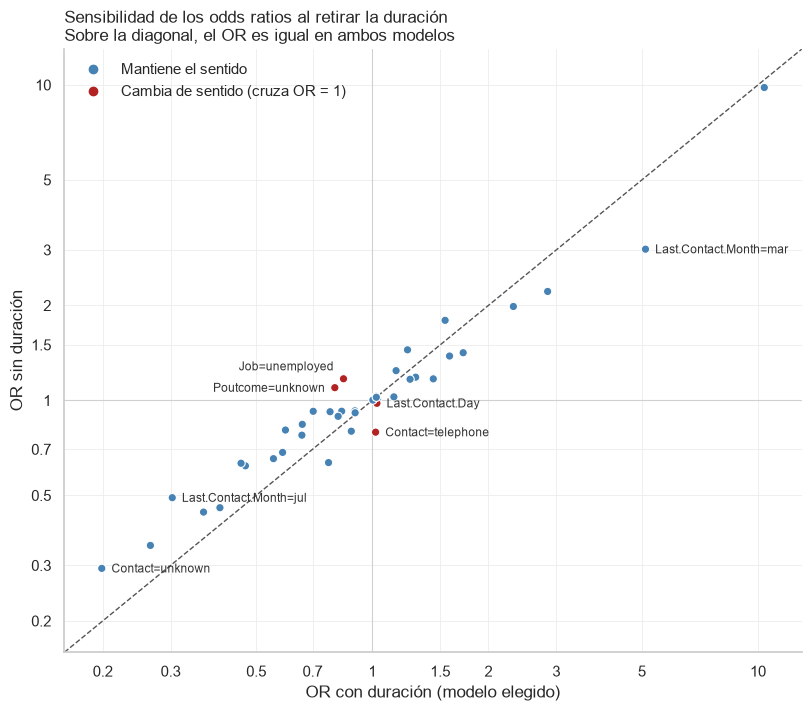

In [ ]:
cambio_log = np.log(sensibilidad['OR sin duración'] / sensibilidad['OR con duración']).abs()
destacados = cambio_log.sort_values(ascending=False).head(4).index.union(
    sensibilidad.index[sensibilidad['Cambia de sentido']])
colores_sens = np.where(sensibilidad['Cambia de sentido'], color_elegido, color_significativo)
fig_sens, eje_sens = plt.subplots(figsize=(8, 7), layout='constrained')
limites = [sensibilidad[['OR con duración', 'OR sin duración']].min().min() * 0.8,
           sensibilidad[['OR con duración', 'OR sin duración']].max().max() * 1.25]
eje_sens.plot(limites, limites, color='#555555', linestyle='--', linewidth=1)
eje_sens.axvline(1, color='#d0d0d0', linewidth=0.8)
eje_sens.axhline(1, color='#d0d0d0', linewidth=0.8)
eje_sens.scatter(sensibilidad['OR con duración'], sensibilidad['OR sin duración'],
                 c=colores_sens, s=36, zorder=3, edgecolor='white', linewidth=0.8)
ultima_altura = {'izquierda': [], 'derecha': []}
for termino in sensibilidad.loc[destacados].sort_values('OR sin duración').index:
    x_punto, y_punto = sensibilidad.loc[termino, ['OR con duración', 'OR sin duración']]
    hay_espacio = np.log10(x_punto / limites[0]) > 0.5
    lado = 'izquierda' if (y_punto > x_punto and hay_espacio) else 'derecha'
    desplazamiento = 0
    for altura in ultima_altura[lado]:
        if abs(np.log10(y_punto) - altura) < 0.035:
            desplazamiento += 9
    ultima_altura[lado].append(np.log10(y_punto))
    eje_sens.annotate(termino, (x_punto, y_punto),
                      xytext=(-7 if lado == 'izquierda' else 7, desplazamiento - 3),
                      textcoords='offset points', fontsize=8.5, color='#333333',
                      ha='right' if lado == 'izquierda' else 'left')
eje_sens.set_xscale('log')
eje_sens.set_yscale('log')
eje_sens.set_xlim(limites)
eje_sens.set_ylim(limites)
marcas_sens = [t for t in [0.2, 0.3, 0.5, 0.7, 1, 1.5, 2, 3, 5, 10] if limites[0] <= t <= limites[1]]
for eje_formato in (eje_sens.xaxis, eje_sens.yaxis):
    eje_formato.set_major_locator(plt.FixedLocator(marcas_sens))
    eje_formato.set_minor_locator(plt.NullLocator())
    eje_formato.set_major_formatter(FuncFormatter(lambda valor, _: f'{valor:g}'))
eje_sens.set_xlabel('OR con duración (modelo elegido)')
eje_sens.set_ylabel('OR sin duración')
eje_sens.set_title('Sensibilidad de los odds ratios al retirar la duración\n'
                   'Sobre la diagonal, el OR es igual en ambos modelos', loc='left', fontsize=12)
eje_sens.grid(color='#ececec', linewidth=0.6)
eje_sens.spines[['top', 'right']].set_visible(False)
eje_sens.legend(handles=[
    Line2D([], [], color=color_significativo, marker='o', linestyle='none', label='Mantiene el sentido'),
    Line2D([], [], color=color_elegido, marker='o', linestyle='none', label='Cambia de sentido (cruza OR = 1)'),
], loc='upper left', frameon=False)
fig_sens.savefig(ruta_anexos / 'interpretacion_sensibilidad_sin_duracion.png', dpi=200,
                 bbox_inches='tight', facecolor='white')
plt.show()

**Qué se observa:**

* Sin la duración el AUC baja de 0,9061 a 0,7658 y la Average Precision de 0,5411 a 0,3966. Una parte importante del ordenamiento depende de información posterior a la llamada, aunque la información previa sigue discriminando de forma moderada.
* Los efectos principales mantienen su dirección: éxito previo (10,38 a 9,81), préstamo de vivienda (0,469 a 0,620), canal desconocido (0,199 a 0,293) y número de contactos (0,901 a 0,926). En general los OR se acercan a 1, algo esperable en regresión logística al omitir una variable muy predictiva.
* Solo cuatro términos cruzan OR = 1 (`Last.Contact.Day`, `Job=unemployed`, `Contact=telephone` y `Poutcome=unknown`), todos débiles o no significativos en el glm.
* Para elegir clientes antes de llamarlos, el desempeño esperado se parece más a un AUC de 0,77 que a uno de 0,91.

## 3.9 Síntesis de la interpretación

El modelo es globalmente significativo (LR = 7.642,86, 42 gl, p < 0,001), 12 de las 16 variables son significativas al 5% y no hay multicolinealidad problemática (VIF máximo de 6,15).

* **Aumentan los odds de suscripción:** el éxito en la campaña anterior (×10,4), el contacto en marzo, octubre o septiembre (×5,1, ×2,8 y ×2,3 frente a abril), cada minuto de llamada (×1,41), ser estudiante (×1,72), la educación terciaria (×1,59) y ser soltero (×1,30).
* **Los reducen:** el canal de contacto no registrado (−80 %), el préstamo de vivienda (−53 %), el préstamo personal (−41 %), el contacto en mayo (−54 % frente a abril), cada contacto adicional en la campaña (−10 %) y ocupaciones como `housemaid`, `entrepreneur`, `self-employed` y `blue-collar` (entre −30 % y −45 %).
* **Sin efecto** una vez controladas las demás variables: edad, `Pdays`, `Previous` e incumplimiento de crédito.

El perfil con mayor probabilidad de adquirir el depósito es el de un cliente que ya aceptó una oferta anterior, no tiene préstamos y fue contactado por celular sin necesidad de muchas llamadas. Estos resultados son asociaciones, no efectos causales, el mes y el canal reflejan cómo se ejecutó la campaña y la duración solo se conoce después de la llamada (sin ella, el AUC baja a 0,77), además las probabilidades del modelo balanceado deben corregirse antes de usarse: el promedio pasa de 30,9% a 12,2%.